# Notebook 01: Exploratory Data Analysis & Preprocessing

**Project:** AI-Based Personalized Learning and Student Performance Predictor (P38)

**Purpose of this notebook:**
1. Load and validate the dataset
2. Perform exploratory data analysis (EDA)
3. Engineer the target variable (mastery level)
4. Visualize feature distributions and relationships

**Dataset:** [Students Performance in Exams](https://www.kaggle.com/datasets/spscientist/students-performance-in-exams) — 1,000 student records with 5 categorical features and 3 exam scores.

---
## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set consistent plot style and display options
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("All imports successful!")

All imports successful!


---
## 2. Data Loading

We use `pathlib.Path` for the file path so the code works regardless of the operating system. The path is **relative** to this notebook's location (`notebooks/`), so `../data/` goes up one level to the project root and into the `data/` folder.

In [2]:
# Define path relative to this notebook
DATA_PATH = Path("../data/StudentsPerformance.csv")

# Verify the file exists before loading
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. "
        "Please download it from Kaggle and place it in data/StudentsPerformance.csv"
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
print(f"Source: {DATA_PATH.resolve()}")

Dataset loaded successfully!
Rows: 1000
Columns: 8
Source: /home/waterball/Desktop/AI-Student-Performance-Predictor/data/StudentsPerformance.csv


---
## 3. Data Validation

Before any analysis, we need to verify:
- The dataset has the expected shape (1000 rows × 8 columns)
- Column names and data types are correct
- There are no missing values or duplicates
- Categorical columns have sensible unique values
- Numerical scores are within valid ranges (0–100)

### 3.1 First Look at the Data

In [3]:
# Display the first 5 rows to see what we're working with
display(df.head())

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


### 3.2 Column Types and Memory Usage

In [4]:
# df.info() shows the column names, non-null counts, and data types
# This helps us confirm:
#   - 5 columns are categorical (object/string type)
#   - 3 columns are numerical (int64 type for scores)
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


### 3.3 Missing Values

In [5]:
# Check for missing values in every column
# A value of 0 means no missing data in that column
missing = df.isnull().sum()

print("Missing values per column:")
display(missing)

total_missing = missing.sum()
if total_missing == 0:
    print("\n✅ No missing values found. The dataset is complete.")
else:
    print(f"\n⚠️ Found {total_missing} missing values. These need to be handled.")

Missing values per column:


gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


✅ No missing values found. The dataset is complete.


### 3.4 Duplicate Rows

In [6]:
# Check for exact duplicate rows
# Duplicates could mean data entry errors or repeated records
dup_count = df.duplicated().sum()

print(f"Duplicate rows: {dup_count}")
if dup_count == 0:
    print("✅ No duplicate rows found.")
else:
    print(f"⚠️ Found {dup_count} duplicate rows. Consider investigating.")

Duplicate rows: 0
✅ No duplicate rows found.


### 3.5 Categorical Feature Values

Let's verify that each categorical column has sensible, expected values and see how many categories each feature has.

In [7]:
# List the 5 categorical features we'll use as model inputs
CATEGORICAL_FEATURES = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course"
]

# For each categorical column, show unique values and their counts
for col in CATEGORICAL_FEATURES:
    print(f"\n--- {col} ---")
    print(f"Unique values ({df[col].nunique()}):")
    display(df[col].value_counts())


--- gender ---
Unique values (2):


gender
female    518
male      482
Name: count, dtype: int64


--- race/ethnicity ---
Unique values (5):


race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64


--- parental level of education ---
Unique values (6):


parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64


--- lunch ---
Unique values (2):


lunch
standard        645
free/reduced    355
Name: count, dtype: int64


--- test preparation course ---
Unique values (2):


test preparation course
none         642
completed    358
Name: count, dtype: int64

### 3.6 Numerical Score Ranges

Exam scores should be between 0 and 100. Let's verify this and look at summary statistics.

In [8]:
SCORE_COLUMNS = ["math score", "reading score", "writing score"]

# Summary statistics for the three score columns
print("Summary Statistics for Exam Scores:")
display(df[SCORE_COLUMNS].describe())

# Verify all scores are in the valid range [0, 100]
for col in SCORE_COLUMNS:
    min_val = df[col].min()
    max_val = df[col].max()
    in_range = (min_val >= 0) and (max_val <= 100)
    status = "✅" if in_range else "⚠️"
    print(f"{status} {col}: range [{min_val}, {max_val}]")

Summary Statistics for Exam Scores:


,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


✅ math score: range [0, 100]
✅ reading score: range [17, 100]
✅ writing score: range [10, 100]


---
## Checkpoint 2 Summary

**What we verified:**
- Dataset has 1,000 rows and 8 columns
- 5 categorical features (our model inputs) and 3 numerical scores
- Zero missing values, zero duplicate rows
- All exam scores are within the valid 0–100 range
- Each categorical feature has a reasonable number of categories

**Next steps (in the cells below):** Exploratory Data Analysis and Target Engineering (Checkpoint 3)

---
## 4. Exploratory Data Analysis (EDA)

EDA helps us understand patterns and relationships in the dataset before building a machine learning model.

### 4.1 Distribution of Exam Scores

We will visualize mathematics, reading, and writing scores separately to understand how student performance varies across subjects.

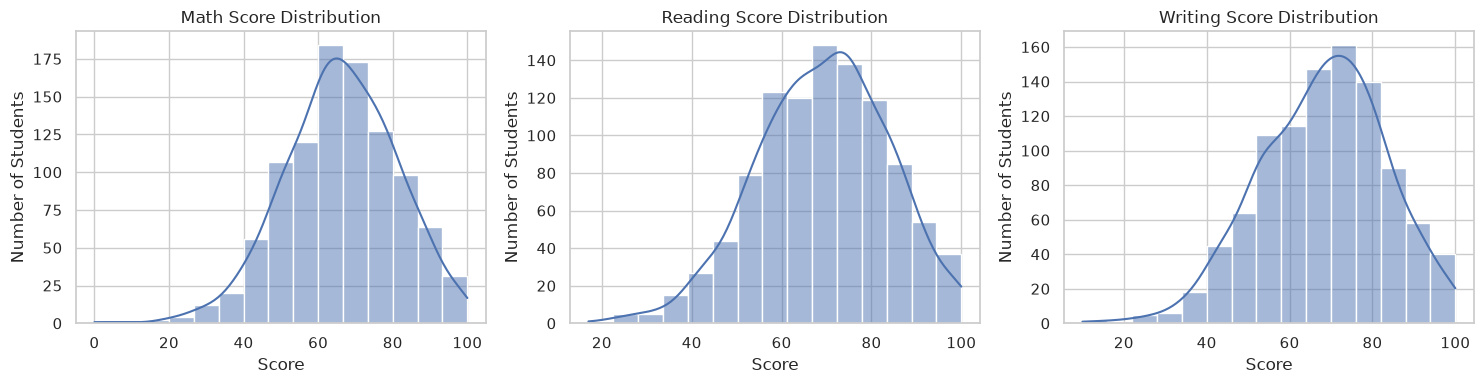

In [9]:
# Plot the distribution of scores in all three subjects
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column in zip(axes, SCORE_COLUMNS):
    sns.histplot(df[column], bins=15, kde=True, ax=ax)
    ax.set_title(f"{column.title()} Distribution")
    ax.set_xlabel("Score")
    ax.set_ylabel("Number of Students")

plt.tight_layout()
plt.show()

**Key observations**
- Mathematics scores are concentrated mainly around 60–75.
- Reading and writing scores appear concentrated at somewhat higher ranges.
- Histograms help us understand score distributions and identify patterns such as skewness.

**Remember:** `histplot()` displays score frequencies, while `kde=True` adds a smoothed estimate of the distribution.

### 4.2 Correlation Between Exam Scores

Correlation measures how strongly two numerical variables move together. We will use a correlation matrix and heatmap to examine the relationships between the three exam scores.

A positive correlation means higher values in one subject tend to be associated with higher values in another. Correlation does not establish causation.

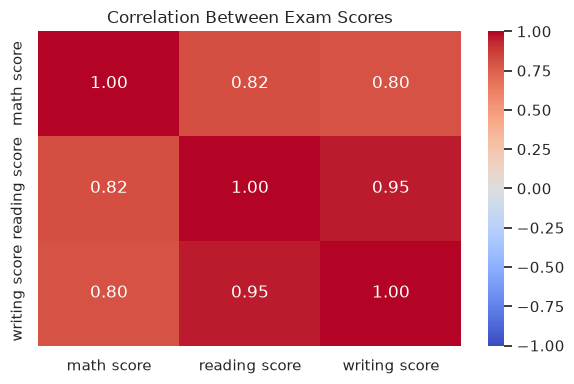

In [10]:
# Calculate pairwise correlations between the exam scores
score_correlation = df[SCORE_COLUMNS].corr()

# Visualize the correlation matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    score_correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Between Exam Scores")
plt.tight_layout()
plt.show()

**Key observations**
- Mathematics–reading correlation: 0.82.
- Mathematics–writing correlation: 0.80.
- Reading–writing correlation: 0.95.

All three pairs show positive relationships, with the strongest relationship between reading and writing.

**Remember:** Correlation measures the strength and direction of a linear relationship. It does not establish causation.

### 4.3 Performance Across Student Groups

We will compare average exam scores across test preparation status and parental education levels.

A boxplot shows the median, spread, and potential outliers in each group. These comparisons describe patterns in the dataset and do not establish that a particular factor causes higher or lower scores.

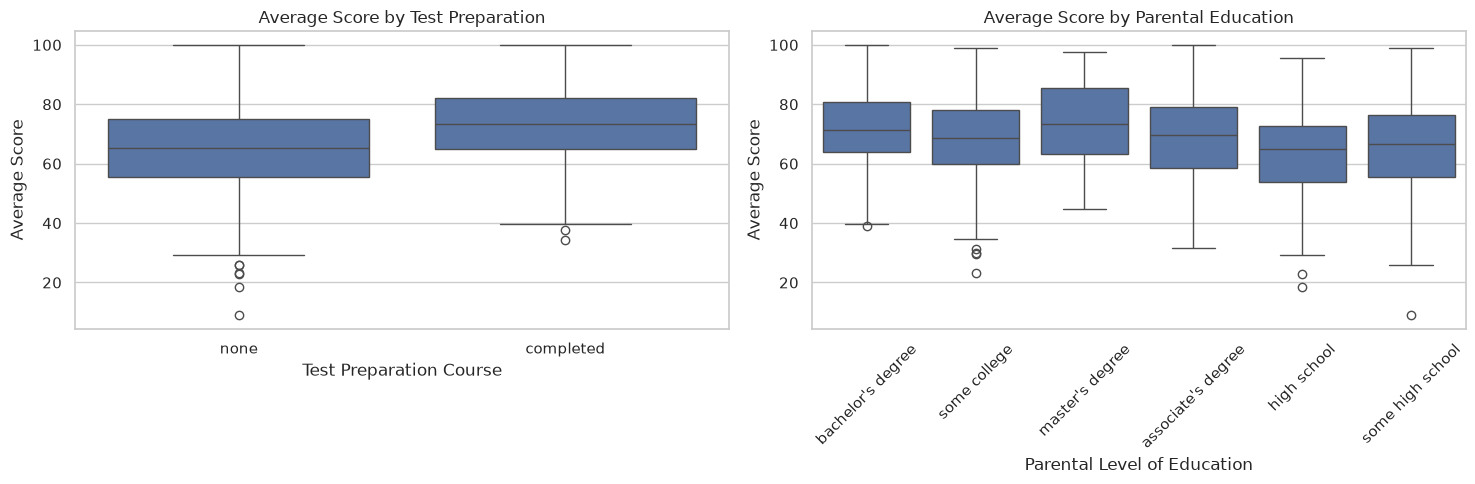

In [12]:
# Calculate the average of the three exam scores for each student
df["average_score"] = df[SCORE_COLUMNS].mean(axis=1)

# Compare average scores across two categorical features
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(
    data=df,
    x="test preparation course",
    y="average_score",
    ax=axes[0]
)
axes[0].set_title("Average Score by Test Preparation")
axes[0].set_xlabel("Test Preparation Course")
axes[0].set_ylabel("Average Score")

sns.boxplot(
    data=df,
    x="parental level of education",
    y="average_score",
    ax=axes[1]
)
axes[1].set_title("Average Score by Parental Education")
axes[1].set_xlabel("Parental Level of Education")
axes[1].set_ylabel("Average Score")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**Remember**
- `average_score` is a derived feature calculated from mathematics, reading, and writing scores.
- Boxplots compare the distribution of a numerical variable across categories.
- Differences between groups indicate associations, not necessarily causal effects.

### 4.4 Creating the Mastery-Level Target

The dataset does not contain predefined mastery labels. We will create them from each student's average mathematics, reading, and writing score.

- Low: average score below 50
- Medium: average score from 50 to below 75
- High: average score of 75 or above

These are engineered labels chosen for this project, not official categories supplied by the dataset.

In [13]:
# Assign a mastery category using the agreed score thresholds
df["mastery_level"] = pd.cut(
    df["average_score"],
    bins=[-np.inf, 50, 75, np.inf],
    labels=["Low", "Medium", "High"],
    right=False
)

# Display the number and percentage of students in each category
mastery_counts = df["mastery_level"].value_counts().reindex(
    ["Low", "Medium", "High"],
    fill_value=0
)

mastery_summary = pd.DataFrame({
    "Number of Students": mastery_counts,
    "Percentage": (mastery_counts / len(df) * 100).round(2)
})

display(mastery_summary)

,Number of Students,Percentage
mastery_level,,
Low,103,10.3
Medium,573,57.3
High,324,32.4


What the code does:
- pd.cut() divides numerical average scores into the three categories.
- right=False makes the intervals left-inclusive and right-exclusive. Thus, a score of exactly 50 is Medium, and a score of exactly 75 is High.
- value_counts() counts students in each category.
- Dividing by the dataset size and multiplying by 100 gives the percentage.

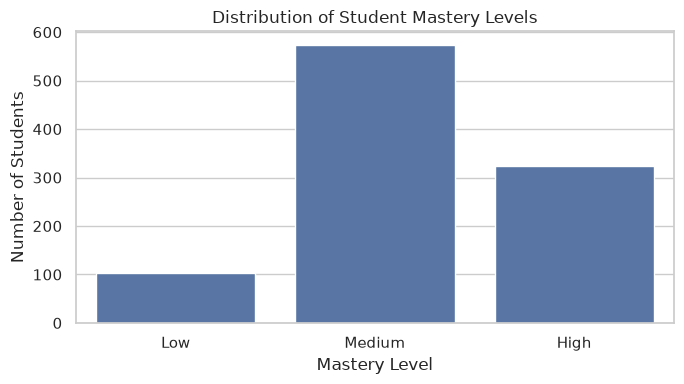

In [14]:
# Visualize the number of students in each mastery category
plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="mastery_level",
    order=["Low", "Medium", "High"]
)

plt.title("Distribution of Student Mastery Levels")
plt.xlabel("Mastery Level")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

**Key observations**
- Low: 103 students (10.3%).
- Medium: 573 students (57.3%).
- High: 324 students (32.4%).
- Medium is the majority class, while Low is the minority class.

**Important concepts**
- Target engineering: creating labels from existing data using defined rules.
- Class imbalance: some target classes have substantially more observations than others.
- The mastery labels are engineered for this project; they are not original dataset labels.

**Why this matters:** Accuracy alone may hide poor predictions for the minority class. We will also evaluate macro-F1 and per-class precision, recall, and F1-score.